# CDAC Machine Learning — Day 8
## Problem: Temperature vs Operating / Energy Cost
### Non-Linear Modeling with Polynomial Regression

---

### Problem Scenario & Objectives
In real-world facilities engineering and HVAC management, electricity/energy consumption exhibits a distinct non-linear relationship with outdoor ambient temperature:
1. **Freezing Weather (-10°C to 0°C)**: High heating expenses driving operating costs up (₹220 down to ₹110).
2. **Comfort Zone (15°C to 20°C)**: Minimal heating or air conditioning is needed, reaching the lowest operating cost (~₹35 - ₹40).
3. **Hot Weather (25°C to 40°C)**: Heavy air conditioning demand causes costs to rise again up to ₹160.

This forms a characteristic **U-shaped parabola** (Degree 2 polynomial relationship).

#### Learning Goals:
- Understand why Simple Linear Regression (Degree 1) **underfits** U-shaped data.
- Use `scikit-learn`'s `PolynomialFeatures` to engineer higher-order power features ($[T] \to [T, T^2]$).
- Build clean, reproducible pipelines using `make_pipeline`.
- Evaluate model quality across polynomial degrees using **RMSE** and **$R^2$ Score**.
- Extract the mathematical formula: $\text{Cost}(T) = \beta_0 + \beta_1 T + \beta_2 T^2$.
- Predict operating costs on intermediate, unseen temperatures.
- Visualize actual data points, the polynomial curve, and linear baseline using `matplotlib` and `seaborn`.


In [1]:
# 1. Imports and Global Configuration
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["font.size"] = 11

print("✓ All libraries imported successfully!")


✓ All libraries imported successfully!


---
## Step 1: Dataset Formulation
We define the 11 observations recorded from the facility management sensor logs:
- **Independent Feature $X$**: Ambient Temperature in degrees Celsius (°C).
- **Dependent Target $y$**: Total facility operating / energy cost.

> **Important Scikit-Learn Rule**:
> - Feature matrix $X$ must be a **2D array/DataFrame** of shape `(n_samples, n_features)`. We write `df[["temp"]]` with double brackets.
> - Target vector $y$ must be a **1D array/Series** of shape `(n_samples,)`. We write `df["cost"]` with single brackets.


In [2]:
# 2. Define the Dataset
data = {
    "temp": [-10, -5, 0, 5, 10, 15, 20, 25, 30, 35, 40],
    "cost": [220, 160, 110, 70, 45, 35, 40, 65, 65, 105, 160]
}

df = pd.DataFrame(data)
X = df[["temp"]]  # 2D DataFrame: shape (11, 1)
y = df["cost"]    # 1D Series: shape (11,)

print("Dataset Summary:")
print(f"X shape: {X.shape} | y shape: {y.shape}\n")
display(df.T)


Dataset Summary:
X shape: (11, 1) | y shape: (11,)



,0,1,2,3,4,5,6,7,8,9,10
temp,-10,-5,0,5,10,15,20,25,30,35,40
cost,220,160,110,70,45,35,40,65,65,105,160


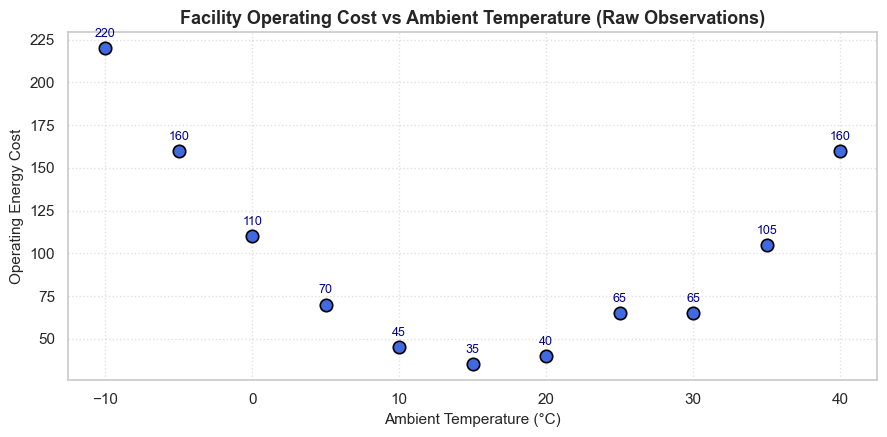

In [3]:
# 3. Exploratory Visualization of the Raw Data
plt.figure(figsize=(9, 4.5))
plt.scatter(df["temp"], df["cost"], color="royalblue", s=80, edgecolors="black", linewidth=1.2, zorder=5)

# Annotate points
for t, c in zip(df["temp"], df["cost"]):
    plt.annotate(f"{c}", (t, c), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, color="darkblue")

plt.title("Facility Operating Cost vs Ambient Temperature (Raw Observations)", fontsize=13, fontweight="bold")
plt.xlabel("Ambient Temperature (°C)", fontsize=11)
plt.ylabel("Operating Energy Cost", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


---
## Step 2: Feature Transformation with `PolynomialFeatures`
Linear Regression can only fit a straight hyperplane ($y = \beta_0 + \beta_1 x$). To enable it to fit non-linear curves, we apply **Feature Expansion**:
$$\begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{bmatrix} \xrightarrow{\text{PolynomialFeatures(degree=2)}} \begin{bmatrix} x_1 & x_1^2 \\ x_2 & x_2^2 \\ \vdots & \vdots \\ x_n & x_n^2 \end{bmatrix}$$

Notice:
- `include_bias=False`: We omit the column of ones $[1, 1, \dots, 1]$ because `LinearRegression(fit_intercept=True)` already provides the bias intercept $\beta_0$.


In [4]:
# 4. Feature Transformation Demonstration
poly_demo = PolynomialFeatures(degree=2, include_bias=False)
X_poly_sample = poly_demo.fit_transform(X)

# Build a readable preview table
feature_names = poly_demo.get_feature_names_out(["temp"])
df_poly = pd.DataFrame(X_poly_sample, columns=feature_names)
df_poly["cost (target)"] = y.values

print("Transformed Feature Matrix (Degree 2):")
display(df_poly.head(7))


Transformed Feature Matrix (Degree 2):


,temp,temp^2,cost (target)
0,-10.0,100.0,220
1,-5.0,25.0,160
2,0.0,0.0,110
3,5.0,25.0,70
4,10.0,100.0,45
5,15.0,225.0,35
6,20.0,400.0,40


---
## Step 3: Model Comparison across Polynomial Degrees (1 to 4)
We evaluate polynomial models from Degree 1 to Degree 4 using:
- **RMSE (Root Mean Squared Error)**: Standard deviation of residuals; lower is better:
  $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
- **$R^2$ Score (Coefficient of Determination)**: Percentage of variance explained ($0 \le R^2 \le 1$):
  $$R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$$


In [5]:
# 5. Comparing Degrees 1 to 4
degrees = [1, 2, 3, 4]
results = []

for deg in degrees:
    # Build pipeline: Polynomial Features -> Linear Regression
    model = make_pipeline(
        PolynomialFeatures(degree=deg, include_bias=False),
        LinearRegression()
    )
    model.fit(X, y)
    y_pred = model.predict(X)
    
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2 = r2_score(y, y_pred)
    
    diagnosis = "Severe Underfitting" if deg == 1 else "Optimal Fit (Parabola)" if deg == 2 else "Potential Overfitting"
    results.append({
        "Degree": deg,
        "Formula Type": f"Degree {deg} Polynomial",
        "RMSE": round(rmse, 3),
        "R2_Score": round(r2, 4),
        "Diagnosis": diagnosis
    })

df_results = pd.DataFrame(results)
display(df_results)


,Degree,Formula Type,RMSE,R2_Score,Diagnosis
0,1,Degree 1 Polynomial,53.756,0.1138,Severe Underfitting
1,2,Degree 2 Polynomial,5.979,0.9890,Optimal Fit (Parabola)
2,3,Degree 3 Polynomial,5.823,0.9896,Potential Overfitting
3,4,Degree 4 Polynomial,5.739,0.9899,Potential Overfitting


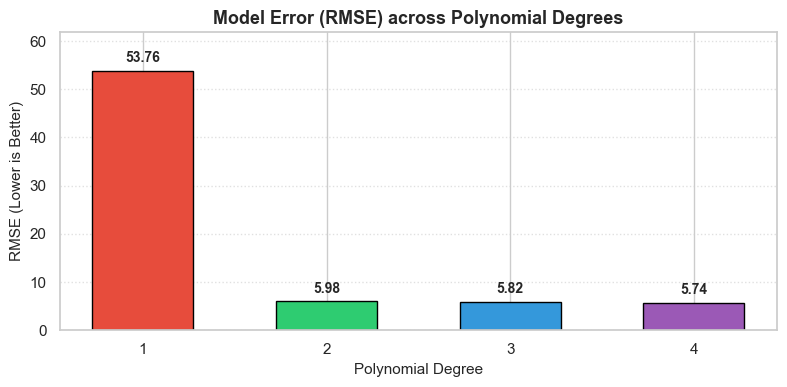

In [6]:
# 6. Visualize Error Reduction by Degree
plt.figure(figsize=(8, 4))
colors = ["#e74c3c", "#2ecc71", "#3498db", "#9b59b6"]
bars = plt.bar(df_results["Degree"].astype(str), df_results["RMSE"], color=colors, edgecolor="black", width=0.55)

plt.title("Model Error (RMSE) across Polynomial Degrees", fontsize=13, fontweight="bold")
plt.xlabel("Polynomial Degree", fontsize=11)
plt.ylabel("RMSE (Lower is Better)", fontsize=11)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, h + 1.2, f"{h:.2f}", ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.ylim(0, max(df_results["RMSE"]) * 1.15)
plt.grid(True, linestyle=":", alpha=0.6, axis='y')
plt.tight_layout()
plt.show()


---
## Step 4: Quadratic Polynomial Model Inspection (Degree 2)
Degree 2 is the most robust and physically interpretable model for this problem:
$$\text{Cost}(T) = \beta_0 + \beta_1 \cdot T + \beta_2 \cdot T^2$$

Where:
- $\beta_0$ (**Intercept**): Baseline facility cost when ambient temperature is exactly $0^\circ\text{C}$.
- $\beta_1$ (**Linear Coefficient**): Downward slope driven by decreasing heating requirements as weather warms.
- $\beta_2$ (**Quadratic Coefficient**): Upward curvature rate driven by cooling / AC electricity demands.


In [7]:
# 7. Fit Final Degree 2 Model and Extract Learned Parameters
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly_model.fit(X, y)

# Access the linear regression step inside the pipeline
lr_step = poly_model.named_steps["linearregression"]
b0 = lr_step.intercept_
b1, b2 = lr_step.coef_

print("=" * 65)
print("Fitted Quadratic Equation (Degree 2):")
print(f"  Cost(T) = {b0:.2f} + ({b1:.2f} * T) + ({b2:.2f} * T²)")
print("=" * 65)
print(f"  - Intercept (b0):           {b0:.2f}  (Estimated cost at 0°C)")
print(f"  - Linear Coeff (b1):        {b1:.2f}  (Downward heating reduction rate)")
print(f"  - Quadratic Coeff (b2):     {b2:.2f}  (Upward cooling acceleration rate)")
print("=" * 65)


Fitted Quadratic Equation (Degree 2):
  Cost(T) = 109.95 + (-8.48 * T) + (0.24 * T²)
  - Intercept (b0):           109.95  (Estimated cost at 0°C)
  - Linear Coeff (b1):        -8.48  (Downward heating reduction rate)
  - Quadratic Coeff (b2):     0.24  (Upward cooling acceleration rate)


---
## Step 5: Predictions on Intermediate & Unseen Temperatures
We use our fitted model to predict operating costs at intermediate temperatures not present in the training set:
- $-7.5^\circ\text{C}$ (Deep sub-zero)
- $-2.5^\circ\text{C}$ (Sub-zero)
- $+2.5^\circ\text{C}$ (Chilly)
- $+7.5^\circ\text{C}$ (Cool)
- $+12.0^\circ\text{C}$ (Mild)


In [8]:
# 8. Predict on Unseen Intermediate Temperatures
new_temperatures = pd.DataFrame({"temp": [-7.5, -2.5, 2.5, 7.5, 12.0]})
predicted_costs = poly_model.predict(new_temperatures)

df_predictions = new_temperatures.copy()
df_predictions["Predicted_Cost"] = np.round(predicted_costs, 2)

display(df_predictions)


,temp,Predicted_Cost
0,-7.5,187.14
1,-2.5,132.66
2,2.5,90.27
3,7.5,59.98
4,12.0,43.07


---
## Step 6: Publication-Quality Visualization
We now generate a smooth mathematical plot:
- **`np.linspace(min - 2, max + 2, 300)`**: Evaluates the model at 300 evenly spaced points to produce a smooth, continuous curve.
- **Linear Baseline (Orange dashed line)**: Visually confirms why linear regression fails to capture the physical reality.
- **Polynomial Fit (Green solid line)**: Demonstrates the parabolic fit capturing 98.9% of total variance.


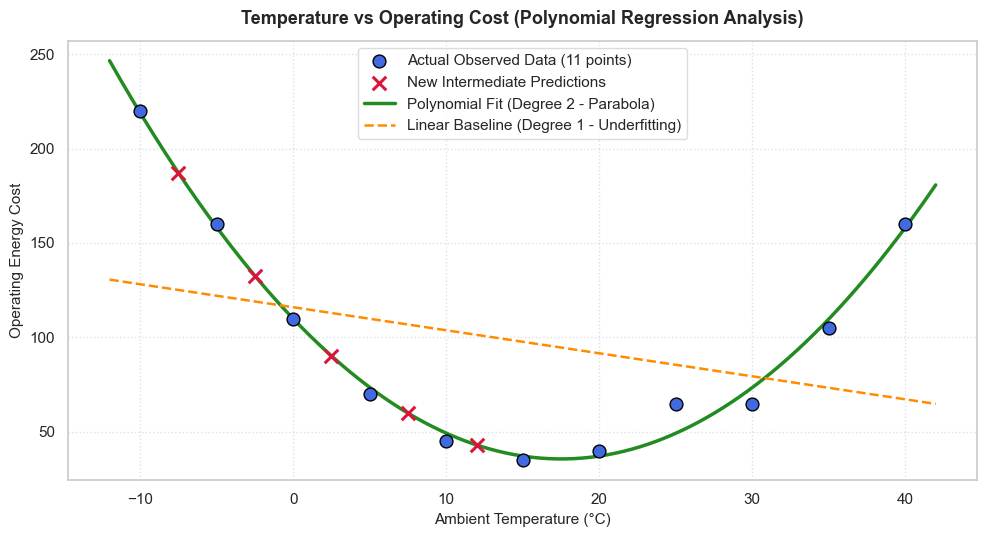

In [9]:
# 9. Plot Fitted Curve vs Linear Baseline
x_smooth = pd.DataFrame({"temp": np.linspace(df["temp"].min() - 2, df["temp"].max() + 2, 300)})
y_smooth = poly_model.predict(x_smooth)

linear_model = LinearRegression().fit(X, y)
y_linear_smooth = linear_model.predict(x_smooth)

plt.figure(figsize=(10, 5.5))

# Actual observations
plt.scatter(df["temp"], df["cost"], color="royalblue", s=85, edgecolors="black", linewidth=1, zorder=5, label="Actual Observed Data (11 points)")

# Predictions
plt.scatter(new_temperatures["temp"], predicted_costs, color="crimson", marker="x", s=95, linewidth=2.2, zorder=6, label="New Intermediate Predictions")

# Curves
plt.plot(x_smooth["temp"], y_smooth, color="forestgreen", linewidth=2.5, label="Polynomial Fit (Degree 2 - Parabola)")
plt.plot(x_smooth["temp"], y_linear_smooth, color="darkorange", linestyle="--", linewidth=1.8, label="Linear Baseline (Degree 1 - Underfitting)")

# Formatting
plt.title("Temperature vs Operating Cost (Polynomial Regression Analysis)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Ambient Temperature (°C)", fontsize=11)
plt.ylabel("Operating Energy Cost", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, facecolor="white", edgecolor="lightgray", loc="upper center")
plt.tight_layout()

# Save figure to file
plt.savefig("temperature_cost_polynomial_fit.png", dpi=150)
plt.show()


---
## Summary of Key CDAC ML Takeaways

| Concept | Explanation | Scikit-Learn Syntax |
| :--- | :--- | :--- |
| **Pipeline Pattern** | Bundles preprocessing with estimator | `make_pipeline(PolynomialFeatures(2), LinearRegression())` |
| **Bias Flag** | Omits duplicate column of ones | `PolynomialFeatures(degree=2, include_bias=False)` |
| **Extract Weights** | Access inner step in pipeline | `pipeline.named_steps["linearregression"].coef_` |
| **Underfitting** | Model too simple; high bias | Degree 1 straight line ($R^2 = 0.1138$) |
| **Overfitting Risk** | Model fits noise; high variance | Degree > 2 bends through random fluctuations |
| **Smooth Plotting** | Dense point grid for curves | `np.linspace(start, stop, 300)` |
